In [1]:
# Core libraries for data manipulation, numerical computation, and visualization.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Assign descriptive names to the eight fields in the Auto MPG dataset.
cols = ['MPG','Cylinders','Displacement','Horsepower','Weight',
                'Acceleration', 'Model Year', 'Origin']

# Parse the whitespace-delimited source file; "?" denotes a missing measurement.
df = pd.read_csv('./auto-mpg.data', names=cols, na_values = "?",
                comment = '\t',
                sep= " ",
                skipinitialspace=True)

# Retain an independent working copy for data exploration and preparation.
full_data = df.copy()

In [5]:
full_data.head()

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Origin
0,18.0,8,307.0,130.0,3504.0,12.0,70,1
1,15.0,8,350.0,165.0,3693.0,11.5,70,1
2,18.0,8,318.0,150.0,3436.0,11.0,70,1
3,16.0,8,304.0,150.0,3433.0,12.0,70,1
4,17.0,8,302.0,140.0,3449.0,10.5,70,1


## Exploratory Data Analysis

In [8]:
# Inspect column types and non-null counts before selecting preprocessing steps.
full_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   MPG           398 non-null    float64
 1   Cylinders     398 non-null    int64  
 2   Displacement  398 non-null    float64
 3   Horsepower    392 non-null    float64
 4   Weight        398 non-null    float64
 5   Acceleration  398 non-null    float64
 6   Model Year    398 non-null    int64  
 7   Origin        398 non-null    int64  
dtypes: float64(5), int64(3)
memory usage: 25.0 KB


In [10]:
# Quantify missing observations in each field.
df.isnull().sum()

MPG             0
Cylinders       0
Displacement    0
Horsepower      6
Weight          0
Acceleration    0
Model Year      0
Origin          0
dtype: int64

In [12]:
# Review distributional summaries to understand scale, spread, and potential anomalies.
full_data.describe()

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Origin
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000,3.000000


<Axes: xlabel='Horsepower'>

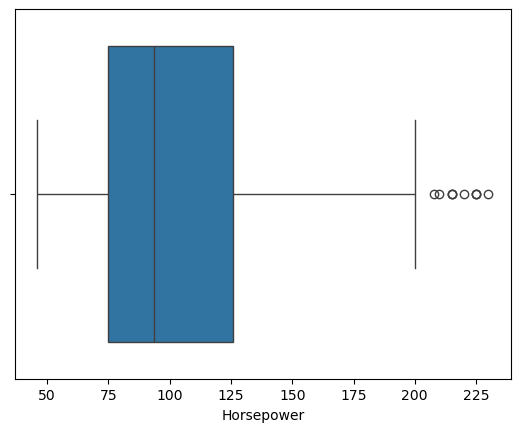

In [14]:
# Inspect horsepower for extreme values before choosing a missing-value strategy.
sns.boxplot(x=full_data['Horsepower'])

In [16]:
# Use the median to impute the six missing horsepower values.
# The median is less sensitive to extreme observations than the mean.
median = full_data['Horsepower'].median()
full_data['Horsepower'] = full_data['Horsepower'].fillna(median)
full_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   MPG           398 non-null    float64
 1   Cylinders     398 non-null    int64  
 2   Displacement  398 non-null    float64
 3   Horsepower    398 non-null    float64
 4   Weight        398 non-null    float64
 5   Acceleration  398 non-null    float64
 6   Model Year    398 non-null    int64  
 7   Origin        398 non-null    int64  
dtypes: float64(5), int64(3)
memory usage: 25.0 KB


## Categorical Feature Distributions

In [19]:
# Compare the relative frequency of each cylinder configuration.
full_data['Cylinders'].value_counts()/ len(full_data)

Cylinders
4    0.512563
8    0.258794
6    0.211055
3    0.010050
5    0.007538
Name: count, dtype: float64

In [21]:
full_data["Origin"].value_counts()

Origin
1    249
3     79
2     70
Name: count, dtype: int64

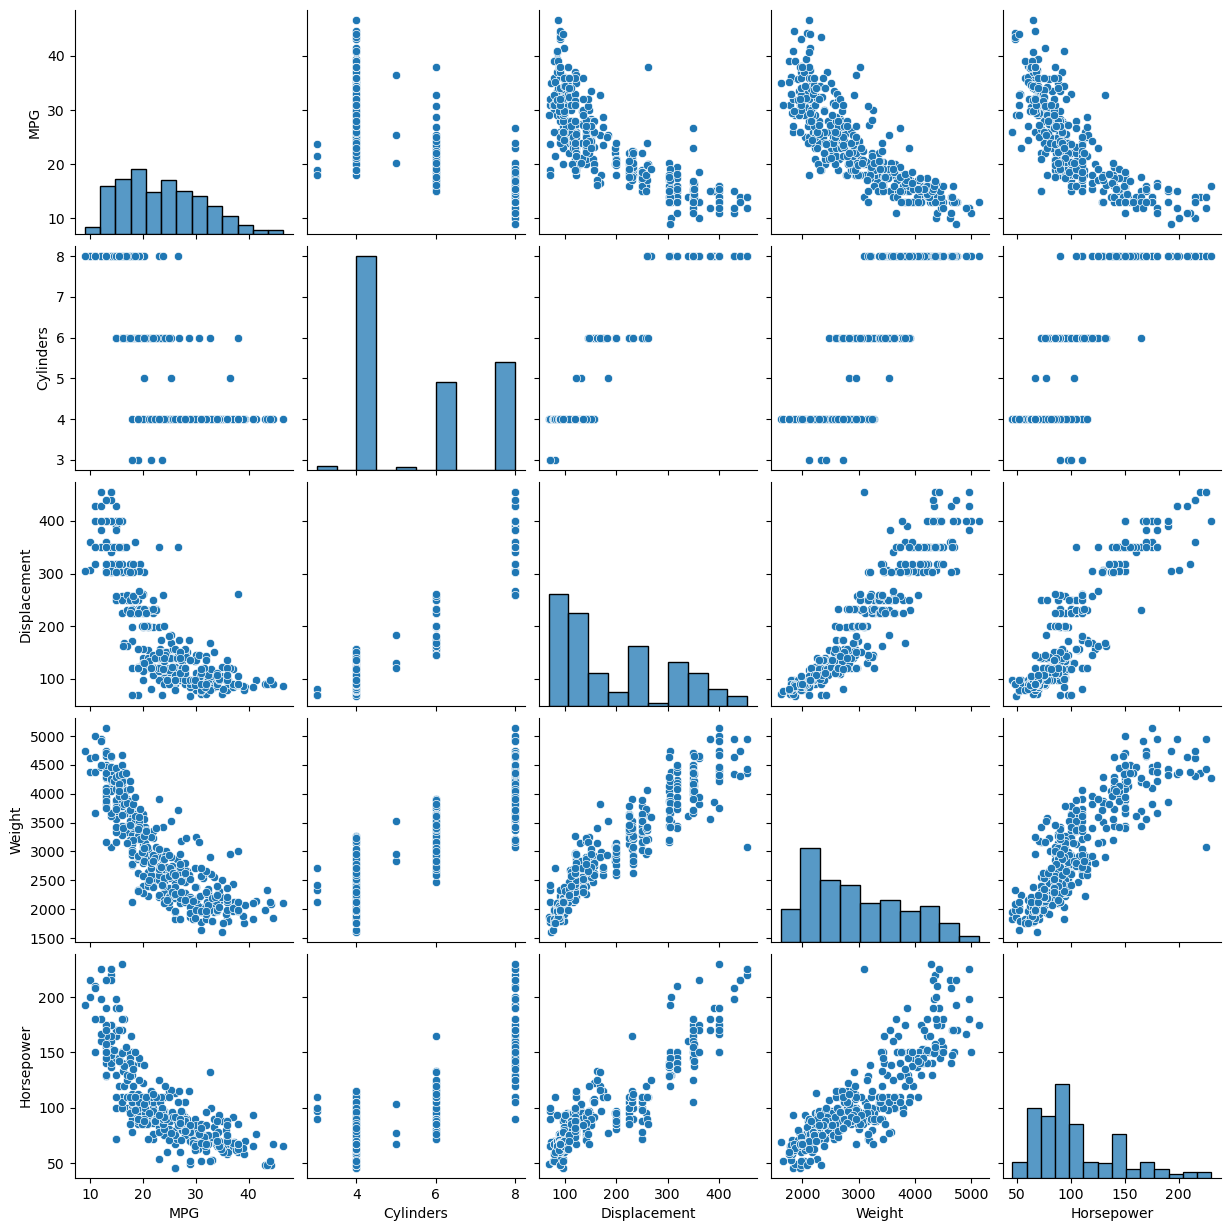

In [23]:
# Examine pairwise relationships among MPG and selected vehicle attributes.
sns.pairplot(full_data[["MPG", "Cylinders", "Displacement", "Weight", "Horsepower"]]).diag_kind = "kde" 

## Establishing the Holdout Set

In [26]:
# Create an initial random holdout split for comparison with stratified sampling.
from sklearn.model_selection import train_test_split
train_set, test_set = train_test_split(full_data, test_size = 0.2, random_state = 42)

test_set.shape

(80, 8)

In [28]:
train_set["Cylinders"].value_counts() / len(train_set)

Cylinders
4    0.509434
8    0.248428
6    0.220126
3    0.012579
5    0.009434
Name: count, dtype: float64

In [30]:
test_set['Cylinders'].value_counts() / len(test_set)

Cylinders
4    0.525
8    0.300
6    0.175
Name: count, dtype: float64

## Stratified Train–Test Split

In [33]:
# Preserve the observed cylinder-count proportions in both partitions.
from sklearn.model_selection import StratifiedShuffleSplit
split = StratifiedShuffleSplit(n_splits = 1, test_size = 0.2, random_state = 42)
for train_index, test_index in split.split(df, df["Cylinders"]):
    strat_train_set = df.loc[train_index]
    strat_test_set = df.loc[test_index]

In [35]:
strat_test_set.shape

(80, 8)

In [37]:
##checking for cylinder category distribution in training and test set

strat_train_set['Cylinders'].value_counts() / len(strat_train_set)

Cylinders
4    0.512579
8    0.257862
6    0.210692
5    0.009434
3    0.009434
Name: count, dtype: float64

In [39]:
strat_test_set["Cylinders"].value_counts()/ len(strat_test_set)

Cylinders
4    0.5125
8    0.2625
6    0.2125
3    0.0125
Name: count, dtype: float64

In [41]:
# Map the numeric origin codes to readable region labels for categorical analysis.
train_set['Origin'] = train_set['Origin'].map({1: "USA", 2: "Europe", 3: "Japan"})
train_set.sample(10)

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Origin
214,13.0,8,302.0,130.0,3870.0,15.0,76,USA
62,13.0,8,350.0,165.0,4274.0,12.0,72,USA
147,24.0,4,90.0,75.0,2108.0,15.5,74,Europe
195,29.0,4,85.0,52.0,2035.0,22.2,76,USA
376,37.0,4,91.0,68.0,2025.0,18.2,82,Japan
322,46.6,4,86.0,65.0,2110.0,17.9,80,Japan
108,20.0,4,97.0,88.0,2279.0,19.0,73,Japan
385,38.0,4,91.0,67.0,1995.0,16.2,82,Japan
235,26.0,4,97.0,75.0,2265.0,18.2,77,Japan
323,27.9,4,156.0,105.0,2800.0,14.4,80,USA


## Encoding Categorical Features

In [44]:
train_set = pd.get_dummies(train_set, prefix='', prefix_sep='')
train_set.head()

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Europe,Japan,USA
3,16.0,8,304.0,150.0,3433.0,12.0,70,False,False,True
18,27.0,4,97.0,88.0,2130.0,14.5,70,False,True,False
376,37.0,4,91.0,68.0,2025.0,18.2,82,False,True,False
248,36.1,4,91.0,60.0,1800.0,16.4,78,False,True,False
177,23.0,4,115.0,95.0,2694.0,15.0,75,True,False,False


In [46]:
train_data = strat_train_set.copy()
train_data.head()

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Origin
145,32.0,4,83.0,61.0,2003.0,19.0,74,3
151,31.0,4,79.0,67.0,2000.0,16.0,74,2
388,26.0,4,156.0,92.0,2585.0,14.5,82,1
48,18.0,6,250.0,88.0,3139.0,14.5,71,1
114,26.0,4,98.0,90.0,2265.0,15.5,73,2


## Correlation Analysis

In [49]:
# Rank the training-set features by their linear correlation with the MPG target.
corr_matrix = train_data.corr()
corr_matrix["MPG"].sort_values(ascending = False) 

MPG             1.000000
Origin          0.582654
Model Year      0.577636
Acceleration    0.411989
Cylinders      -0.765693
Horsepower     -0.777978
Displacement   -0.800063
Weight         -0.822723
Name: MPG, dtype: float64

## Feature Engineering Exploration

In [52]:
# Explore ratio-based features that may capture vehicle efficiency relationships.
train_data['displacement_on_power'] = train_data['Displacement'] / train_data['Horsepower']
train_data['weight_on_cylinder'] = train_data['Weight'] / train_data['Cylinders']
train_data['acceleration_on_power'] = train_data['Acceleration'] / train_data['Horsepower']
train_data['acceleration_on_cyl'] = train_data['Acceleration'] / train_data['Cylinders']

# Assess how these engineered attributes correlate with the target.
corr_matrix = train_data.corr()
corr_matrix["MPG"].sort_values(ascending = False) 

MPG                      1.000000
acceleration_on_cyl      0.718888
acceleration_on_power    0.699560
Origin                   0.582654
Model Year               0.577636
Acceleration             0.411989
weight_on_cylinder       0.002289
displacement_on_power   -0.562725
Cylinders               -0.765693
Horsepower              -0.777978
Displacement            -0.800063
Weight                  -0.822723
Name: MPG, dtype: float64

In [54]:
# Separate predictors from the continuous MPG target using the stratified training partition.
data = strat_train_set.drop("MPG", axis=1)
data_labels = strat_train_set["MPG"].copy()
data

,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Origin
145,4,83.0,61.0,2003.0,19.0,74,3
151,4,79.0,67.0,2000.0,16.0,74,2
388,4,156.0,92.0,2585.0,14.5,82,1
48,6,250.0,88.0,3139.0,14.5,71,1
114,4,98.0,90.0,2265.0,15.5,73,2
...,...,...,...,...,...,...,...
147,4,90.0,75.0,2108.0,15.5,74,2
156,8,400.0,170.0,4668.0,11.5,75,1
395,4,135.0,84.0,2295.0,11.6,82,1
14,4,113.0,95.0,2372.0,15.0,70,3


In [56]:
def preprocess_origin_cols(df):
    """Convert encoded vehicle-origin values into categorical region labels."""
    df = df.copy()

    df["Origin"] = df["Origin"].map({
        1: "USA",
        2: "Europe",
        3: "Japan"
    })

    return df

data_tr = preprocess_origin_cols(data)
data_tr.head()

,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Origin
145,4,83.0,61.0,2003.0,19.0,74,Japan
151,4,79.0,67.0,2000.0,16.0,74,Europe
388,4,156.0,92.0,2585.0,14.5,82,USA
48,6,250.0,88.0,3139.0,14.5,71,USA
114,4,98.0,90.0,2265.0,15.5,73,Europe


In [58]:
data_tr.info()

<class 'pandas.core.frame.DataFrame'>
Index: 318 entries, 145 to 362
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Cylinders     318 non-null    int64  
 1   Displacement  318 non-null    float64
 2   Horsepower    314 non-null    float64
 3   Weight        318 non-null    float64
 4   Acceleration  318 non-null    float64
 5   Model Year    318 non-null    int64  
 6   Origin        318 non-null    object 
dtypes: float64(4), int64(2), object(1)
memory usage: 19.9+ KB


In [60]:
## Isolating the Origin column
data_cat = data_tr[['Origin']]
data_cat.head()

,Origin
145,Japan
151,Europe
388,USA
48,USA
114,Europe


In [62]:
# Fit a one-hot encoder to the origin field and represent each region as a binary feature.
from sklearn.preprocessing import OneHotEncoder
cat_encoder = OneHotEncoder()
data_cat_1hot = cat_encoder.fit_transform(data_cat)
data_cat_1hot   # Sparse output avoids allocating unnecessary zero values.

<318x3 sparse matrix of type '<class 'numpy.float64'>'
	with 318 stored elements in Compressed Sparse Row format>

In [64]:
data_cat_1hot.toarray()[:5]

array([[0., 1., 0.],
       [1., 0., 0.],
       [0., 0., 1.],
       [0., 0., 1.],
       [1., 0., 0.]])

In [66]:
cat_encoder.categories_

[array(['Europe', 'Japan', 'USA'], dtype=object)]

In [68]:
## Segregating the numerical column
num_data = data.drop("Origin", axis =1)
num_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 318 entries, 145 to 362
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Cylinders     318 non-null    int64  
 1   Displacement  318 non-null    float64
 2   Horsepower    314 non-null    float64
 3   Weight        318 non-null    float64
 4   Acceleration  318 non-null    float64
 5   Model Year    318 non-null    int64  
dtypes: float64(4), int64(2)
memory usage: 17.4 KB


In [70]:
# Fit median imputation on the numerical training predictors.
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")
imputer.fit(num_data)

SimpleImputer(strategy='median')

In [72]:
## median of all column
imputer.statistics_

array([   4. ,  146. ,   92. , 2844. ,   15.5,   76. ])

In [74]:
X = imputer.transform(num_data)
X

array([[   4. ,   83. ,   61. , 2003. ,   19. ,   74. ],
       [   4. ,   79. ,   67. , 2000. ,   16. ,   74. ],
       [   4. ,  156. ,   92. , 2585. ,   14.5,   82. ],
       ...,
       [   4. ,  135. ,   84. , 2295. ,   11.6,   82. ],
       [   4. ,  113. ,   95. , 2372. ,   15. ,   70. ],
       [   6. ,  146. ,  120. , 2930. ,   13.8,   81. ]])

In [76]:
## converting the 2d array back into dataframe
data_tr = pd.DataFrame(X, columns=num_data.columns,
                          index=num_data.index)
data_tr.info()

<class 'pandas.core.frame.DataFrame'>
Index: 318 entries, 145 to 362
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Cylinders     318 non-null    float64
 1   Displacement  318 non-null    float64
 2   Horsepower    318 non-null    float64
 3   Weight        318 non-null    float64
 4   Acceleration  318 non-null    float64
 5   Model Year    318 non-null    float64
dtypes: float64(6)
memory usage: 17.4 KB


In [78]:
# Define a scikit-learn-compatible transformer for domain-informed ratio features.
from sklearn.base import BaseEstimator, TransformerMixin

class CustomAttrAdder(BaseEstimator, TransformerMixin):
    """Add acceleration-to-cylinder and optional acceleration-to-horsepower ratios."""

    def __init__(self, add_acc_on_power=True):
        self.add_acc_on_power = add_acc_on_power

    def fit(self, X, y=None):
        # No training statistics are required to construct these deterministic ratios.
        return self

    def transform(self, X):
        # Work on a copy so the caller's input frame remains unchanged.
        X = X.copy()

        X["acceleration_on_cyl"] = (
            X["Acceleration"] / X["Cylinders"]
        )

        if self.add_acc_on_power:
            X["acceleration_on_power"] = (
                X["Acceleration"] / X["Horsepower"]
            )

        return X

    
    def get_feature_names_out(self, input_features=None):
        """Return original and engineered feature names."""

        if input_features is None:
            input_features = self.feature_names_in_

        feature_names = list(input_features)
        feature_names.append("acceleration_on_cyl")

        if self.add_acc_on_power:
            feature_names.append("acceleration_on_power")

        return np.asarray(feature_names, dtype=object)



In [80]:
# Build the numerical preprocessing workflow: imputation, feature generation, then scaling.
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Keep transformed outputs as pandas objects where supported by the installed sklearn version.
from sklearn import set_config
set_config(transform_output="pandas")

numerics = ['float64', 'int64']
num_data = data_tr.select_dtypes(include=numerics)

num_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy="median")),
        ('attrs_adder', CustomAttrAdder()),
        ('std_scaler', StandardScaler()),
    ])

num_data_tr = num_pipeline.fit_transform(num_data)
num_data_tr.iloc[0]

Cylinders               -0.856578
Displacement            -1.078045
Horsepower              -1.151930
Weight                  -1.172203
Acceleration             1.215869
Model Year              -0.544364
acceleration_on_cyl      1.295655
acceleration_on_power    1.709527
Name: 145, dtype: float64

In [82]:
# Apply numerical and categorical transformations to their respective columns.
from sklearn.compose import ColumnTransformer

num_attrs = list(num_data)
cat_attrs = ["Origin"]

# Combine numerical processing with one-hot encoding of the vehicle's region of origin.
full_pipeline = ColumnTransformer([
        ("num", num_pipeline, num_attrs),
        ("cat", OneHotEncoder(sparse_output=False), cat_attrs),
    ])

#prepared_data = full_pipeline.fit_transform(data)
#prepared_data.iloc[0]


In [84]:
def num_pipeline_transformer(data):
    """Select numeric predictors and define their imputation/engineering/scaling steps.

    Parameters
    ----------
    data : pandas.DataFrame
        Predictor data before numerical preprocessing.

    Returns
    -------
    num_attrs : pandas.DataFrame
        Numeric columns selected for transformation.
    num_pipeline : sklearn.pipeline.Pipeline
        Unfitted numerical preprocessing pipeline.
    """
    numerics = ['float64', 'int64']
    num_attrs = data.select_dtypes(include=numerics)

    num_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy="median")),
        ('attrs_adder', CustomAttrAdder()),
        ('std_scaler', StandardScaler()),
    ])
    return num_attrs, num_pipeline


def pipeline_transformer(data):
    """Build the combined preprocessing pipeline for numeric and origin predictors.

    Parameters
    ----------
    data : pandas.DataFrame
        Training predictors containing numeric fields and the Origin category.

    Returns
    -------
    prepared_data : array-like or pandas.DataFrame
        Transformed feature matrix.
    full_pipeline : sklearn.compose.ColumnTransformer
        Unfitted transformer for consistent processing of future observations.
    """
    cat_attrs = ["Origin"]
    num_attrs, num_pipeline = num_pipeline_transformer(data)
    full_pipeline = ColumnTransformer([
        ("num", num_pipeline, list(num_attrs)),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), cat_attrs),
    ])
    
    return full_pipeline

In [86]:

# Convert Origin codes to categorical labels.
preprocessed_df = preprocess_origin_cols(data)

# Build the preprocessing transformer without fitting it.
full_pipeline = pipeline_transformer(preprocessed_df)


In [88]:
## A reuseable function for all models to pevent writing preprocessing steps repeatedly
def make_model_pipeline(regressor):
    """Combine preprocessing and a regression estimator."""
    return Pipeline([
        ("preprocessing", pipeline_transformer(preprocessed_df)),
        ("regressor", regressor),
    ])


## Regression Model Development

The regression candidates evaluated in this notebook are:

- Linear Regression
- Decision Tree Regressor
- Random Forest Regressor
- Support Vector Regressor (linear kernel)

In [92]:
# Fit a linear regression baseline on the transformed training features.
from sklearn.linear_model import LinearRegression
lin_reg = make_model_pipeline(LinearRegression())

## Baseline Model Evaluation

In [95]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    lin_reg,
    preprocessed_df,
    data_labels,
    scoring="neg_mean_squared_error",
    cv=10
)

lin_reg_rmse_scores = np.sqrt(-scores)
lin_reg_rmse_scores

array([3.42793469, 3.44954043, 3.66512735, 2.59652976, 2.4705213 ,
       2.74516993, 3.32596687, 2.42208917, 3.78133275, 2.8573747 ])

In [97]:
lin_reg.fit(preprocessed_df, data_labels)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('attrs_adder',
                                                                   CustomAttrAdder()),
                                                                  ('std_scaler',
                                                                   StandardScaler())]),
                                                  ['Cylinders', 'Displacement',
                                                   'Horsepower', 'Weight',
                                                   'Acceleration',
                                                   'Model Year']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Origin'])])),
                ('regressor', LinearRegression())])

In [99]:
# Measure training-set error using root mean squared error (RMSE), in MPG units.
from sklearn.metrics import mean_squared_error

mgp_predictions = lin_reg.predict(preprocessed_df)
lin_mse = mean_squared_error(data_labels, mgp_predictions)
lin_rmse = np.sqrt(lin_mse)
lin_rmse

2.9590402225760863

In [101]:
# Compare predictions and observed MPG values for a small training subset.
sample_data = preprocessed_df.iloc[:5]
sample_labels = data_labels.iloc[:5]

# Apply the fitted preprocessing steps before passing the rows to the estimator.

print("Predictions for sample vehicles:", lin_reg.predict(sample_data))

Predictions for sample vehicles: [30.87084533 28.8942444  29.18645219 18.38508216 24.4280997 ]


In [103]:
print("Actual Labels of samples: ", list(sample_labels))

Actual Labels of samples:  [32.0, 31.0, 26.0, 18.0, 26.0]


## Decision Tree Regressor

In [106]:
# Fit a decision tree regressor to capture non-linear feature relationships.
from sklearn.tree import DecisionTreeRegressor

tree_pipeline = make_model_pipeline(
    DecisionTreeRegressor(
        random_state=42,
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5
    )
)

## Decision Tree Evaluation

In [109]:
# Estimate decision-tree generalization error with 10-fold cross-validation.
from sklearn.model_selection import cross_val_score

scores = cross_val_score(tree_pipeline,
                         preprocessed_df,
                         data_labels,
                         scoring="neg_mean_squared_error",
                         cv=10)
tree_reg_rmse_scores = np.sqrt(-scores)
tree_reg_rmse_scores

array([2.17271084, 3.18288178, 3.31765344, 3.32504516, 2.80433458,
       3.28220369, 2.91893916, 2.88314716, 4.37501426, 2.87949148])

In [111]:
# Calculate in-sample RMSE; this is a fit diagnostic, not a generalization estimate.
tree_pipeline.fit(preprocessed_df, data_labels)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('attrs_adder',
                                                                   CustomAttrAdder()),
                                                                  ('std_scaler',
                                                                   StandardScaler())]),
                                                  ['Cylinders', 'Displacement',
                                                   'Horsepower', 'Weight',
                                                   'Acceleration',
                                                   'Model Year']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Origin'])])),
                ('regressor',
                 DecisionTreeRegressor(max_depth=5, min_samples_leaf=5,
                                       min_samples_split=10,
                                       random_state=42))])

In [113]:
mgp_predictions = tree_pipeline.predict(preprocessed_df)

tree_mse = mean_squared_error(data_labels, mgp_predictions)
tree_rmse = np.sqrt(tree_mse)

tree_rmse

2.220147910925742

In [115]:
tree_reg_rmse_scores.mean()

3.1141421566904386

## Random Forest Regressor

In [118]:
# Train a random forest and estimate its performance across 10 validation folds.
from sklearn.ensemble import RandomForestRegressor

forest_reg = make_model_pipeline(RandomForestRegressor(random_state=42))
forest_reg_cv_scores = cross_val_score(forest_reg,
                                       preprocessed_df,
                                       data_labels,
                                       scoring='neg_mean_squared_error',
                                       cv=10)

forest_reg_rmse_scores = np.sqrt(-forest_reg_cv_scores)
forest_reg_rmse_scores.mean()

2.6028707654058945

In [119]:
forest_reg.fit(preprocessed_df, data_labels)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('attrs_adder',
                                                                   CustomAttrAdder()),
                                                                  ('std_scaler',
                                                                   StandardScaler())]),
                                                  ['Cylinders', 'Displacement',
                                                   'Horsepower', 'Weight',
                                                   'Acceleration',
                                                   'Model Year']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Origin'])])),
                ('regressor', RandomForestRegressor(random_state=42))])

## Support Vector Regression

In [121]:
# Evaluate a linear-kernel support vector regressor using 10-fold cross-validation.
from sklearn.svm import SVR

svm_reg = make_model_pipeline(SVR(kernel="linear"))

svm_cv_scores = cross_val_score(svm_reg, preprocessed_df, data_labels,
                                scoring='neg_mean_squared_error',
                                cv=10)
svm_rmse_scores = np.sqrt(-svm_cv_scores)
svm_rmse_scores.mean()

3.085657152083455

In [124]:
svm_reg.fit(preprocessed_df, data_labels)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('attrs_adder',
                                                                   CustomAttrAdder()),
                                                                  ('std_scaler',
                                                                   StandardScaler())]),
                                                  ['Cylinders', 'Displacement',
                                                   'Horsepower', 'Weight',
                                                   'Acceleration',
                                                   'Model Year']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Origin'])])),
                ('regressor', SVR(kernel='linear'))])

In [127]:
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "SVR"
    ],
    "Mean CV RMSE": [
        lin_reg_rmse_scores.mean(),
        tree_reg_rmse_scores.mean(),
        forest_reg_rmse_scores.mean(),
        svm_rmse_scores.mean()
    ],
    "CV RMSE Std": [
        lin_reg_rmse_scores.std(),
        tree_reg_rmse_scores.std(),
        forest_reg_rmse_scores.std(),
        svm_rmse_scores.std()
    ]
})

model_comparison.sort_values(
    by="Mean CV RMSE"
)

,Model,Mean CV RMSE,CV RMSE Std
2,Random Forest,2.602871,0.583762
0,Linear Regression,3.074159,0.484948
3,SVR,3.085657,0.486433
1,Decision Tree,3.114142,0.532678


## Random Forest Hyperparameter Search

In [130]:
# Search a compact set of Random Forest configurations using cross-validation.
from sklearn.model_selection import GridSearchCV


param_grid = [
    {
        'regressor__n_estimators': [3, 10, 30],
        'regressor__max_features': [2, 4, 6, 8]
    },
    {
        'regressor__bootstrap': [False],
        'regressor__n_estimators': [3, 10],
        'regressor__max_features': [2, 3, 4]
    },
]

forest_pipeline = make_model_pipeline(
    RandomForestRegressor(random_state=42)
)

grid_search = GridSearchCV(
    forest_pipeline,
    param_grid,
    scoring='neg_mean_squared_error',
    return_train_score=True,
    cv=10
)

grid_search.fit(preprocessed_df, data_labels)


GridSearchCV(cv=10,
             estimator=Pipeline(steps=[('preprocessing',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('attrs_adder',
                                                                                          CustomAttrAdder()),
                                                                                         ('std_scaler',
                                                                                          StandardScaler())]),
                                                                         ['Cylinders',
                                                                          'Displacement',
                                                                          'Horsepower',
                                                                          'Weight',
                                                                          'Acceleration',
                                                                          'Model '
                                                                          'Year']),
                                                                        ('cat',
                                                                         OneHotEncoder(handle_unknown='ignore',
                                                                                       sparse_output=False),
                                                                         ['Origin'])])),
                                       ('regressor',
                                        RandomForestRegressor(random_state=42))]),
             param_grid=[{'regressor__max_features': [2, 4, 6, 8],
                          'regressor__n_estimators': [3, 10, 30]},
                         {'regressor__bootstrap': [False],
                          'regressor__max_features': [2, 3, 4],
                          'regressor__n_estimators': [3, 10]}],
             return_train_score=True, scoring='neg_mean_squared_error')

In [131]:
grid_search.best_params_

{'regressor__max_features': 8, 'regressor__n_estimators': 30}

In [134]:
grid_search.best_estimator_

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('attrs_adder',
                                                                   CustomAttrAdder()),
                                                                  ('std_scaler',
                                                                   StandardScaler())]),
                                                  ['Cylinders', 'Displacement',
                                                   'Horsepower', 'Weight',
                                                   'Acceleration',
                                                   'Model Year']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Origin'])])),
                ('regressor',
                 RandomForestRegressor(max_features=8, n_estimators=30,
                                       random_state=42))])

In [136]:
# Convert each mean cross-validation MSE to RMSE for direct comparison across configurations.
cv_scores = grid_search.cv_results_

for mean_score, params in zip(cv_scores['mean_test_score'], cv_scores["params"]):
    print(np.sqrt(-mean_score), params)

3.550820886084479 {'regressor__max_features': 2, 'regressor__n_estimators': 3}
3.142408746782449 {'regressor__max_features': 2, 'regressor__n_estimators': 10}
2.8746605620097467 {'regressor__max_features': 2, 'regressor__n_estimators': 30}
3.145518943914231 {'regressor__max_features': 4, 'regressor__n_estimators': 3}
2.8427001819743096 {'regressor__max_features': 4, 'regressor__n_estimators': 10}
2.7349438529125654 {'regressor__max_features': 4, 'regressor__n_estimators': 30}
3.3309669187488615 {'regressor__max_features': 6, 'regressor__n_estimators': 3}
2.8743834735161173 {'regressor__max_features': 6, 'regressor__n_estimators': 10}
2.787830450381028 {'regressor__max_features': 6, 'regressor__n_estimators': 30}
3.0904194039472874 {'regressor__max_features': 8, 'regressor__n_estimators': 3}
2.7847217892544287 {'regressor__max_features': 8, 'regressor__n_estimators': 10}
2.7079658222527936 {'regressor__max_features': 8, 'regressor__n_estimators': 30}
3.1477629558694673 {'regressor__boot

## Feature Importance Analysis

In [139]:
# Retrieve impurity-based feature importance scores from the selected forest.

# Retrieve the best fitted pipeline.
best_pipeline = grid_search.best_estimator_

# Extract the fitted Random Forest estimator.
best_forest = best_pipeline.named_steps["regressor"]

# Retrieve its impurity-based feature importance scores.
feature_importances = best_forest.feature_importances_

feature_importances

array([0.17370972, 0.27185437, 0.1351405 , 0.213526  , 0.01190661,
       0.11805513, 0.03856075, 0.03203472, 0.0015466 , 0.00234904,
       0.00131655])

In [141]:
feature_names = (
    best_pipeline.named_steps["preprocessing"]
    .get_feature_names_out()
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importances
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df

,Feature,Importance
1,num__Displacement,0.271854
3,num__Weight,0.213526
0,num__Cylinders,0.173710
2,num__Horsepower,0.135141
5,num__Model Year,0.118055
6,num__acceleration_on_cyl,0.038561
7,num__acceleration_on_power,0.032035
4,num__Acceleration,0.011907
9,cat__Origin_Japan,0.002349
8,cat__Origin_Europe,0.001547


## Final Holdout Evaluation

In [144]:
final_model = grid_search.best_estimator_

X_test = strat_test_set.drop("MPG", axis=1)
y_test = strat_test_set["MPG"].copy()

X_test_preprocessed = preprocess_origin_cols(X_test)

final_predictions = final_model.predict(X_test_preprocessed)

final_mse = mean_squared_error(y_test, final_predictions)
final_rmse = np.sqrt(final_mse)

final_rmse

2.8573788979879216

## Reusable Prediction Function

In [147]:
def predict_mpg(config, model):
    """Predict fuel economy for one or more vehicle configurations.

    Parameters
    ----------
    config : dict or pandas.DataFrame
        Vehicle attributes. Dictionary values should be sequences for batch input.
    model : fitted estimator
        Regressor trained on features produced by the fitted preprocessing pipeline.

    Returns
    -------
    numpy.ndarray
        Predicted fuel economy values in miles per gallon.
    """
    if isinstance(config, dict):
        df = pd.DataFrame(config)
    else:
        df = config.copy()

    # Apply the same origin mapping and fitted transformations used during training.
    preproc_df = preprocess_origin_cols(df)
    return model.predict(preproc_df)

In [149]:
# Example batch inference for three hypothetical vehicle configurations.
vehicle_config = {
    'Cylinders': [4, 6, 8],
    'Displacement': [155.0, 160.0, 165.5],
    'Horsepower': [93.0, 130.0, 98.0],
    'Weight': [2500.0, 3150.0, 2600.0],
    'Acceleration': [15.0, 14.0, 16.0],
    'Model Year': [81, 80, 78],
    'Origin': [3, 2, 1]
}

predict_mpg(vehicle_config, final_model)

array([30.87666667, 21.01      , 22.50666667])

## Model Serialization

In [152]:
# Persist the fitted estimator so it can be reloaded for later inference.
import pickle

with open("model.bin", "wb") as f_out:
    pickle.dump(final_model, f_out)

In [154]:
# Reload the saved estimator and verify that it supports the same prediction workflow.
with open("model.bin", "rb") as f_in:
    model = pickle.load(f_in)

predict_mpg(vehicle_config, model)

array([30.87666667, 21.01      , 22.50666667])